In [1]:
import matplotlib.pyplot as plt
import numpy as np
import copy
import EXOSIMS.MissionSim
from astropy.time import Time
from tools.plotKeepoutMap import plotKeepoutMap
import os
if not "DISPLAY" in os.environ.keys():  # Check environment for keys
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
else:
    import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import colors
import argparse
import json
from EXOSIMS.util.read_ipcluster_ensemble import gen_summary
from EXOSIMS.util.read_ipcluster_ensemble import read_all
from numpy import linspace
from matplotlib.ticker import NullFormatter, MaxNLocator
from matplotlib import ticker
import astropy.units as u
import matplotlib.patheffects as PathEffects
import datetime
import re

In [2]:
spec = {
  "seed": 183074220,
  "koAngles_SolarPanel":[56.0,124.0],
  "missionLife": 3,
  "checkKeepoutEnd": True,
  "pupilDiam": 2.37,
  "scienceInstruments": [
    { "name": "imager"
    }
  ],
  "starlightSuppressionSystems": [
    { "name": "HLC-565",
      "koAngles_Sun":[45.0,180.0],
      "koAngles_Earth":[45.0,180.0],
      "koAngles_Moon":[45.0,180.0],
      "koAngles_Small":[1.0,180.0]
    }
  ],
  "observingModes": [
    { "instName": "imager",
      "systName": "HLC-565",
      "detectionMode": True,
      "SNR": 5
    }
  ],
    "modules": {
        "PlanetPopulation": "SAG13",
        "StarCatalog": "EXOCAT1",
        "OpticalSystem": " ",
        "ZodiacalLight": " ",
        "BackgroundSources": " ",
        "PlanetPhysicalModel": " ",
        "Observatory": "ObservatoryTESScsv",
        "TimeKeeping": " ",
        "PostProcessing": " ",
        "Completeness": "BrownCompleteness",
        "TargetList": " ",
        "SimulatedUniverse": "SAG13Universe",
        "SurveySimulation": " ",
        "SurveyEnsemble": " ",
    }
}

In [3]:
sim = EXOSIMS.MissionSim.MissionSim(**copy.deepcopy(spec))
OS = sim.OpticalSystem
obs, TL, TK = sim.Observatory, sim.TargetList, sim.TimeKeeping
star_index = np.random.randint(0, len(TL.Name))
starName = TL.Name[star_index]
#indWhereStarName = np.where(TL.Name == starName)[0]#Get Star Name Ind
koEvaltimes = Time(np.arange(TK.missionStart.value, TK.missionStart.value+TK.missionLife.to('day').value,1),format='mjd')

#Construct koangles
systNames = np.unique([OS.observingModes[x]['syst']['name'] for x in np.arange(len(OS.observingModes))])
koStr     = ["koAngles_Sun", "koAngles_Moon", "koAngles_Earth", "koAngles_Small"]
koangles  = np.zeros([len(systNames),4,2])
for x in np.argsort(systNames):
    rel_mode = list(filter(lambda mode: mode['syst']['name'] == systNames[x], OS.observingModes))[0]
    koangles[x] = np.asarray([rel_mode['syst'][k] for k in koStr])

#Keepouts are calculated here
kogood = np.zeros([1,koEvaltimes.size])
culprit = np.zeros([1,koEvaltimes.size,12])
for t,date in enumerate(koEvaltimes):
    tmpkogood,r_body, r_targ, tmpculprit, koangleArray = obs.keepout(TL, [star_index,star_index], date, koangles, True)
    kogood[0,t] = tmpkogood[0,0,0] #reassign to boolean array of overall visibility
    culprit[0,t,:] = tmpculprit[0,0,0,:] #reassign to boolean array describing visibility of individual keepout perpetrators

#creating an array of visibility based on culprit
sunFault   = [bool(culprit[0,t,0]) for t in np.arange(len(koEvaltimes))]
earthFault = [bool(culprit[0,t,2]) for t in np.arange(len(koEvaltimes))]
moonFault  = [bool(culprit[0,t,1]) for t in np.arange(len(koEvaltimes))]
mercFault  = [bool(culprit[0,t,3]) for t in np.arange(len(koEvaltimes))]
venFault   = [bool(culprit[0,t,4]) for t in np.arange(len(koEvaltimes))]
marsFault  = [bool(culprit[0,t,5]) for t in np.arange(len(koEvaltimes))]
solarPanelFault  = [bool(culprit[0,t,11]) for t in np.arange(len(koEvaltimes))]

Imported SurveySimulation (prototype) from EXOSIMS.Prototypes.SurveySimulation
Numpy random seed is: 183074220
Imported SAG13Universe (implementation) from EXOSIMS.SimulatedUniverse.SAG13Universe
Imported TargetList (prototype) from EXOSIMS.Prototypes.TargetList
Imported EXOCAT1 (implementation) from EXOSIMS.StarCatalog.EXOCAT1
Imported OpticalSystem (prototype) from EXOSIMS.Prototypes.OpticalSystem
Imported ZodiacalLight (prototype) from EXOSIMS.Prototypes.ZodiacalLight
Imported PostProcessing (prototype) from EXOSIMS.Prototypes.PostProcessing
Imported BackgroundSources (prototype) from EXOSIMS.Prototypes.BackgroundSources
Imported BrownCompleteness (implementation) from EXOSIMS.Completeness.BrownCompleteness
Imported SAG13 (implementation) from EXOSIMS.PlanetPopulation.SAG13
Imported PlanetPhysicalModel (prototype) from EXOSIMS.Prototypes.PlanetPhysicalModel
Loading cached completeness file from "/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/SAG13PlanetPhysicalModelBrownCompleteness10000000

/Users/Yael/Desktop/EXOSIMS/EXOSIMS/MissionSim.py:275: UserWarning: 
The following init keywords were not found in any outspec:
	       tessStartTime (ObservatoryTESScsv)

  warnings.warn(warnstr)


Loading cached dynamic completeness array from "/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/SAG13PlanetPhysicalModelEXOCAT113aa09371b58223d301ce046c6aeb69a.dcomp".
Dynamic completeness array loaded from cache.
Imported ObservatoryTESScsv (implementation) from EXOSIMS.Observatory.ObservatoryTESScsv
orbitdatapath is none
    orbitdatapath (/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/tessAdjcsv.p) exists
Imported TimeKeeping (prototype) from EXOSIMS.Prototypes.TimeKeeping
OBendTimes is: [1095.75] d
Loading cached keepout map file from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/koMap_b69908b0a00f36e1a3b3ccf9e94761bf.komap
Keepout Map loaded from cache.
HLC-565
Loading cached fZ from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/BrownCompletenessTargetListOpticalSysteme0f78bfe1e9605be875077ac09febb65_60_HLC-565_60634.0_61729.75.starkfZ
Loading cached fZmins from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/BrownCompletenessTargetListOpticalSysteme0f78bfe1e9605be875077ac09febb65_60_HLC-565_60634.0_61729.75.fZmin
Impor

Starlight Suppression System: 100%|██████████| 1/1 [00:00<00:00, 504.55it/s]


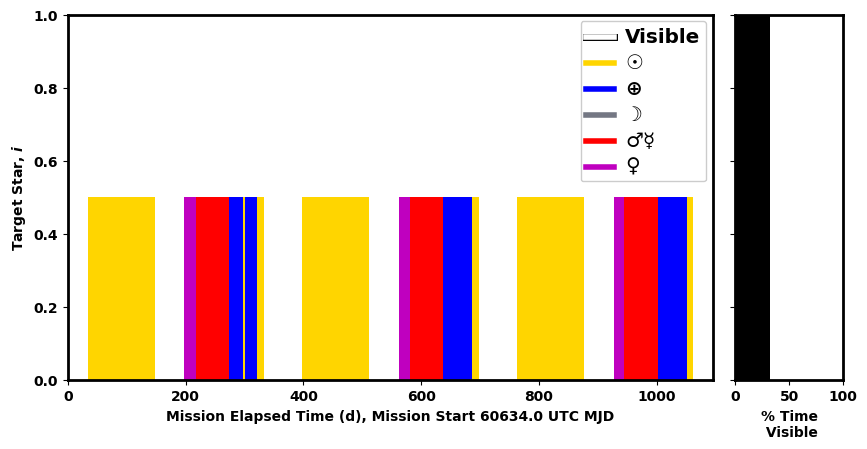

<Figure size 640x480 with 0 Axes>

In [4]:
cmap = colors.ListedColormap(
   ["white", "#FFD500", "blue", "#747783", "red", "m", "red"]
)  # colors for used to indicate a culprit behind keepout
bounds = [0, 1, 2, 3, 4, 5, 6, 7]
norm = colors.BoundaryNorm(bounds, cmap.N)

# creating an array of colors based on culprit
koColor = np.zeros([TL.nStars, len(koEvaltimes)])
koColor = (
    culprit[:, :, 0] * 1
    + culprit[:, :, 2] * 2
    + culprit[:, :, 1] * 3
    + culprit[:, :, 3] * 6
    + culprit[:, :, 4] * 5
    + culprit[:, :, 5] * 4
    + culprit[:, :, 11] * 1
)
koColor.astype("int")


# plotting colors on a 2d map
plt.close(546832183)
fig = plt.figure(546832183, figsize=(10, 5))
fig.subplots_adjust(bottom=0.15)
gs = gridspec.GridSpec(1, 2, width_ratios=[6, 1], height_ratios=[1])
gs.update(wspace=0.06, hspace=0.06)  # set the spacing between axes.
plt.rc("axes", linewidth=2)
plt.rc("lines", linewidth=2)
plt.rcParams["axes.linewidth"] = 2
plt.rc("font", weight="bold")
ax2 = plt.subplot(gs[1])
ax = plt.subplot(gs[0])


if (
    koColor.shape[0] > 100
):  # Determine maximum number of stars to track keepouts for
    NUMBER_Y = 100
else:
    NUMBER_Y = koColor.shape[0]
sInds = np.linspace(
    0, koColor.shape[0], num=NUMBER_Y, endpoint=False, dtype=int
).tolist()
img = plt.imshow(
    koColor[sInds, 0 : int(np.floor(len(koEvaltimes)))],
    aspect="auto",  # 4,
    cmap=cmap,
    interpolation="none",
    origin="lower",
    norm=norm,
)


ax.set_xlabel(
    "Mission Elapsed Time (d), Mission Start %s UTC MJD"
    % (str(TK.missionStart.value)),
    weight="bold",
)
ax.set_ylabel(r"Target Star, $i$", weight="bold")
ax.set_xlim(left=0.0, right=np.max(koEvaltimes).value - TK.missionStart.value)
ax.set_ylim(bottom=0.0, top=NUMBER_Y)

outline = PathEffects.withStroke(linewidth=5, foreground="black")
plt.plot(
    [-1.0, -1.0],
    [-1.0, -1.0],
    color=cmap.colors[0],
    label="Visible",
    path_effects=[outline],
    )
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[1], label="\u2609")
plt.plot(
    [-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[2], label=r"$\oplus$"
)  ##\u2641$')
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[3], label="\u263D")
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[4], label="\u2642\u263F")
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[5], label="\u2640")
# plt.plot([-1.,-1.],[-1.,-1.],color=cmap.colors[6],label=ur'$\u263F$')  duplicate color so appended above
leg = plt.legend(framealpha=1.0)
# get the lines and texts inside legend box
leg_lines = leg.get_lines()
leg_texts = leg.get_texts()
# bulk-set the properties of all lines and texts
plt.setp(leg_lines, linewidth=4)
plt.setp(leg_texts, fontsize="x-large")
nullfmt = NullFormatter()
ax2.yaxis.set_major_formatter(nullfmt)

# Plot horizontal histogram
tTotal = (
    np.max(koEvaltimes).value - TK.missionStart.value
)  # Calculate total time width of koMap
tVis = list()  # stores time visible of each star
for i in np.arange(
    len(sInds)
):  # iterate over all stars and append amount of time each star is visible
    tVis.append(len(np.where(koColor[sInds[i], :] == 0)[0]))

width = np.zeros(len(tVis)) + 1.0
ax2.barh(
    np.arange(len(sInds)) + 0.5,
    np.asarray(tVis, dtype=float) / tTotal * 100.0,
    width,
    align="center",
    color="black",
)
ax2.set_xlim(left=0.0, right=100.0)
ax2.set_ylim(bottom=0.0, top=NUMBER_Y)
ax2.set_xlabel("% Time\n Visible", weight="bold")
#plt.show(block=False)
plt.show()
plt.gcf().canvas.draw()

DT = datetime.datetime
date = str(DT.now())  # ,"utf-8")
date = "".join(
    c + "_" for c in re.split("-|:| ", date)[0:-1]
)  # Removes seconds from date